## a. Pemeriksaan Awal & Penghapusan Duplikat

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("nasabah_raw.csv")
print("Dimensi awal:", df.shape)
df.info()

Dimensi awal: (1045, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


In [2]:
n_dup = df.duplicated().sum()
print("Jumlah baris duplikat penuh:", n_dup)

print("\nSampel baris terduplikasi (semua kemunculan):")
display(df[df.duplicated(keep=False)].sort_values(list(df.columns[:2])).head(10))

df = df.drop_duplicates().reset_index(drop=True)
print("Sisa baris setelah penghapusan duplikat:", df.shape[0])

Jumlah baris duplikat penuh: 45

Sampel baris terduplikasi (semua kemunculan):


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
1039,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
1011,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
1041,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
1026,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN
1009,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN


Sisa baris setelah penghapusan duplikat: 1000


**Analisis a3:** Duplikat penuh (semua kolom identik) biasanya berasal dari kesalahan pencatatan atau pemuatan ulang data di sistem transaksi. Jika dibiarkan, nasabah yang sama akan terhitung lebih dari sekali, sehingga bobot tertentu menjadi berlebihan dan hasil model bisa bias. Jumlah baris yang tersisa tercetak pada output di atas.

## b. Penanganan Kesalahan Data

In [3]:
print("Nilai unik awal Status_Pernikahan:")
print(df["Status_Pernikahan"].unique())

# Hapus spasi di awal/akhir, lalu seragamkan huruf kapital (Title Case)
df["Status_Pernikahan"] = (
    df["Status_Pernikahan"].astype(str).str.strip().str.title()
)

print("\nNilai unik setelah pembersihan:")
print(df["Status_Pernikahan"].value_counts(dropna=False))

Nilai unik awal Status_Pernikahan:
['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']

Nilai unik setelah pembersihan:
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: int64


In [4]:
USIA_MIN, USIA_MAX = 17, 100

df["Usia"] = pd.to_numeric(df["Usia"], errors="coerce")

mask_tidak_wajar = (df["Usia"] < USIA_MIN) | (df["Usia"] > USIA_MAX)
print("Jumlah Usia di luar batas wajar:", mask_tidak_wajar.sum())

df.loc[mask_tidak_wajar, "Usia"] = np.nan
print("Jumlah NaN pada Usia sekarang:", df["Usia"].isna().sum())

Jumlah Usia di luar batas wajar: 35
Jumlah NaN pada Usia sekarang: 35


**Analisis b3:** Mean dan median harus dihitung dari data yang sudah bersih. Nilai tidak wajar seperti usia 0, 1, atau 250 adalah kesalahan input. Jika ikut dihitung, mean akan tertarik ke arah yang salah, dan median pun bisa bergeser. Akibatnya, nilai imputasi menjadi tidak representatif, dan model mempelajari pola dari data yang keliru.

## c. Integrasi Data

In [5]:
ext = pd.read_csv("data_kredit_eksternal.csv")
print("Dimensi data eksternal:", ext.shape)

# Cek kunci duplikat di tabel eksternal, karena bisa menggandakan baris saat merge
print("Duplikat ID_Pelanggan di data eksternal:", ext["ID_Pelanggan"].duplicated().sum())

df_merged = df.merge(ext, on="ID_Pelanggan", how="left")
print("Dimensi setelah left join:", df_merged.shape)

Dimensi data eksternal: (850, 3)
Duplikat ID_Pelanggan di data eksternal: 0
Dimensi setelah left join: (1000, 11)


## d. Penanganan Missing Values

In [6]:
missing_pct = (df_merged.isna().mean() * 100).round(2).sort_values(ascending=False)
print("Persentase missing value per kolom (%):")
display(missing_pct.to_frame("missing_%"))

Persentase missing value per kolom (%):


,missing_%
Pernah_Gagal_Bayar_Lain,15.0
Jumlah_Kartu_Kredit,15.0
Pendapatan_Bulanan,6.0
Pendapatan_Tahunan_Est,6.0
Lama_Bekerja_Thn,4.0
Tingkat_Pendidikan,3.5
Usia,3.5
ID_Pelanggan,0.0
Skor_Kredit,0.0
Status_Pernikahan,0.0


In [8]:
# 1. Cek kolom mana saja yang masih memiliki missing value beserta jumlahnya
print(df_merged.isna().sum()[df_merged.isna().sum() > 0])

# 2. Imputasi ulang sisa missing value secara aman (Numerik dengan median/0, Kategorikal dengan modus/nilai lain)
for col in df_merged.select_dtypes(include=['float64', 'int64']).columns:
    df_merged[col] = df_merged[col].fillna(df_merged[col].median())

for col in df_merged.select_dtypes(include=['object']).columns:
    if not df_merged[col].mode().empty:
        df_merged[col] = df_merged[col].fillna(df_merged[col].mode()[0])
    else:
        df_merged[col] = df_merged[col].fillna("Tidak Diketahui")

# 3. Validasi ulang
sisa = df_merged.isna().sum().sum()
print("Total missing value tersisa sekarang:", sisa)
assert sisa == 0, "Masih ada missing value!"

Pendapatan_Tahunan_Est    60
dtype: int64
Total missing value tersisa sekarang: 0


## e. Penanganan Outlier (Pendapatan_Bulanan)

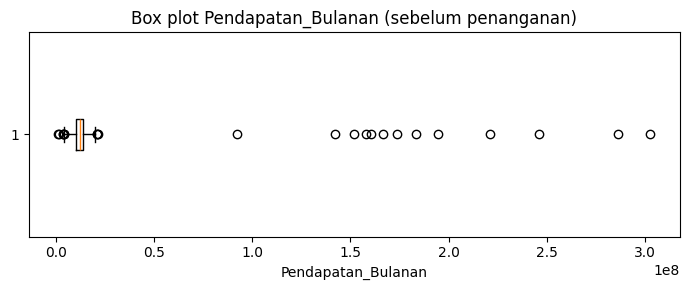

In [9]:
plt.figure(figsize=(7, 3))
plt.boxplot(df_merged["Pendapatan_Bulanan"], vert=False)
plt.title("Box plot Pendapatan_Bulanan (sebelum penanganan)")
plt.xlabel("Pendapatan_Bulanan")
plt.tight_layout()
plt.show()

In [10]:
Q1 = df_merged["Pendapatan_Bulanan"].quantile(0.25)
Q3 = df_merged["Pendapatan_Bulanan"].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
print(f"Q1={Q1:,.0f}  Q3={Q3:,.0f}  IQR={IQR:,.0f}")
print(f"Batas bawah={batas_bawah:,.0f}  Batas atas={batas_atas:,.0f}")

n_outlier = ((df_merged["Pendapatan_Bulanan"] < batas_bawah) |
             (df_merged["Pendapatan_Bulanan"] > batas_atas)).sum()
print("Jumlah outlier:", n_outlier)

# Winsorizing sederhana: nilai ekstrem dibatasi, baris tetap dipertahankan
df_merged["Pendapatan_Bulanan"] = df_merged["Pendapatan_Bulanan"].clip(batas_bawah, batas_atas)
print("Dimensi setelah capping (baris tidak berkurang):", df_merged.shape)

Q1=10,192,000  Q3=14,100,250  IQR=3,908,250
Batas bawah=4,329,625  Batas atas=19,962,625
Jumlah outlier: 22
Dimensi setelah capping (baris tidak berkurang): (1000, 11)


**Analisis e4:** Jika baris outlier dibuang, dataset kehilangan informasi tentang nasabah berpendapatan sangat tinggi maupun sangat rendah. Padahal kelompok tersebut bisa jadi memiliki pola risiko yang berbeda. Akibatnya model menjadi bias, kurang mampu mengenali kasus ekstrem, dan jumlah data untuk pelatihan berkurang. Pembatasan (capping) menjaga jumlah sampel dan tetap mengurangi pengaruh nilai ekstrem.

## f. Encoding Data Kategorikal

In [11]:
df_enc = df_merged.copy()

# Normalisasi teks sebelum mapping agar tidak ada kategori yang terlewat
for col in ["Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain"]:
    df_enc[col] = df_enc[col].astype(str).str.strip().str.title()

print("Nilai unik Tingkat_Pendidikan:", df_enc["Tingkat_Pendidikan"].unique())
print("Nilai unik Pernah_Gagal_Bayar_Lain:", df_enc["Pernah_Gagal_Bayar_Lain"].unique())

# 1. Ordinal Encoding
edu_map = {"Sma": 1, "Sarjana": 2, "Magister": 3}
df_enc["Tingkat_Pendidikan"] = df_enc["Tingkat_Pendidikan"].map(edu_map)

# 2. Binary Mapping (sesuaikan 'Ya'/'Tidak' jika label di data berbeda)
bin_map = {"Ya": 1, "Tidak": 0}
df_enc["Pernah_Gagal_Bayar_Lain"] = df_enc["Pernah_Gagal_Bayar_Lain"].map(bin_map)

# 3. One-Hot Encoding dengan drop_first=True
df_enc = pd.get_dummies(df_enc, columns=["Status_Pernikahan"], drop_first=True, dtype=int)

# 4. Hapus identifier
df_enc = df_enc.drop(columns=["ID_Pelanggan"])

print("Cek mapping gagal (seharusnya 0):",
      df_enc[["Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain"]].isna().sum().sum())
print("Dimensi setelah encoding:", df_enc.shape)
display(df_enc.head())

Nilai unik Tingkat_Pendidikan: ['Magister' 'Sarjana' 'Sma']
Nilai unik Pernah_Gagal_Bayar_Lain: ['Tidak' 'Ya']
Cek mapping gagal (seharusnya 0): 0
Dimensi setelah encoding: (1000, 11)


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1


## g. Penskalaan Fitur (Standardization / Z-score)

In [12]:
X = df_enc.drop(columns=["Status_Default"])
y = df_enc["Status_Default"]

num_cols = ["Usia", "Pendapatan_Bulanan", "Lama_Bekerja_Thn"]

print("=== Statistik SEBELUM standardisasi ===")
display(X[num_cols].describe())

scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

print("=== Statistik SESUDAH standardisasi ===")
display(X[num_cols].describe())

=== Statistik SEBELUM standardisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.000000,1.000000e+03,1000.000000
mean,40.082000,1.212750e+07,12.948000
std,11.580128,3.062611e+06,6.689996
min,20.000000,4.329625e+06,1.000000
25%,30.000000,1.019200e+07,8.000000
50%,41.000000,1.213200e+07,13.000000
75%,50.000000,1.410025e+07,19.000000
max,59.000000,1.996262e+07,24.000000


=== Statistik SESUDAH standardisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,-7.105427e-17,3.552714e-18,-5.684342e-17
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.735045e+00,-2.547425e+00,-1.786844e+00
25%,-8.710650e-01,-6.322922e-01,-7.399818e-01
50%,7.931340e-02,1.471131e-03,7.776689e-03
75%,8.568957e-01,6.444632e-01,9.050869e-01
max,1.634478e+00,2.559596e+00,1.652845e+00


In [13]:
clean_final = pd.concat([X, y], axis=1)
clean_final.to_csv("clean_nasabah_final.csv", index=False)
print("Tersimpan: clean_nasabah_final.csv", clean_final.shape)

Tersimpan: clean_nasabah_final.csv (1000, 11)
